# Notebook 07: Mondrian (Class-Conditional) Conformal Prediction (Phase 3B)

- **Objective**: Objective 3 — Class-Conditional Conformal Prediction & Minority Class Guarantees (RQ2)
- **Research Question 2 (RQ2)**: *Does class-conditional (Mondrian) conformal prediction improve reliability for the minority classes specifically, without rejecting an excessive proportion of cases?*
- **Purpose**: Resolve the minority under-coverage trap discovered in Phase 3A (where Global LAC achieved 89.9% overall coverage but only 77.1% on Pathological and 57.6% on Suspect). Implement Mondrian Conformal Prediction to enforce exact independent coverage guarantees $\ge 1 - \alpha$ for **every individual class**.
- **Golden Rule Compliance**: Base model trained on `Train` ($N=1,275$). Mondrian class quantiles $\hat{q}_k$ computed on `Calibration` ($N=425$). Evaluation conducted strictly once on `Test` ($N=426$).
- **Outputs**:
  1. Class-specific conformity threshold analysis.
  2. Per-class coverage recovery verification (Normal, Suspect, Pathological $\ge 90\%$).
  3. Efficiency trade-off quantification (average set size increase).
  4. Publication-grade 4-panel comparison figure saved to `reports/figures/mondrian_comparison.png`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from src.data.load import load_data
from src.data.split import split_data
from src.conformal.global_cp import sweep_alpha_conformal
from src.conformal.mondrian_cp import (
    MondrianConformalClassifier,
    evaluate_mondrian_coverage,
    sweep_alpha_mondrian,
    plot_mondrian_comparison,
    CLASS_NAMES_DEFAULT
)

print("[OK] Environment loaded successfully with Mondrian Conformal modules.")

[OK] Environment loaded successfully with Mondrian Conformal modules.


## 1. Theoretical Formulation of Mondrian Conformal Prediction

In standard (global) split conformal prediction, a single non-conformity quantile $\hat{q}$ is computed across the entire calibration set:
$$\mathbb{P}(Y \in \Gamma(X)) \ge 1 - \alpha$$
In highly imbalanced datasets like cardiotocography (Normal: 78%, Suspect: 14%, Pathological: 8%), this marginal guarantee is satisfied mostly by getting Normal patients right, while heavily failing on rare Pathological cases.

### Mondrian (Class-Conditional) Framework (Vovk et al., 2005; Sadinle et al., 2019)
Mondrian conformal prediction partitions the calibration set into disjoint categories based on the true label: $\mathcal{D}_k = \{(X_i, Y_i) : Y_i = k\}$ for $k \in \{\text{Normal}, \text{Suspect}, \text{Pathological}\}$.

1. **Class-specific non-conformity scores**:
   $$s_{ik} = 1 - \hat{P}(Y=k \mid X_i) \quad \text{for } i \in \mathcal{D}_k$$
2. **Class-specific quantiles**:
   $$k_c = \lceil (n_k + 1)(1 - \alpha) \rceil, \qquad \hat{q}_k = \begin{cases} s_{(k_c)} & \text{if } k_c \le n_k, \\ +\infty & \text{if } k_c > n_k \end{cases}$$
3. **Prediction set formation**:
   $$\Gamma_{\text{Mondrian}}(x) = \{k \in \mathcal{Y} : \hat{P}(Y=k \mid x) \ge 1 - \hat{q}_k\}$$

**Theoretical Guarantee**:
$$\mathbb{P}(Y \in \Gamma_{\text{Mondrian}}(X) \mid Y = k) \ge 1 - \alpha \quad \forall k \in \mathcal{Y}$$
Every class is guaranteed $\ge 1 - \alpha$ coverage independently!

## 2. Load Data Partitions & Saved Model Artifacts

In [2]:
df = load_data(PROJECT_ROOT / "data/raw/fetal_health.csv")
X_train, X_cal, X_test, y_train, y_cal, y_test = split_data(df, random_state=42)

rf_model = joblib.load(PROJECT_ROOT / "models/random_forest.joblib")
classes = rf_model.classes_

print(f"[Loaded] Base Estimator: {type(rf_model).__name__}")
print(f"[Loaded] Calibration Partition Size: {len(X_cal)} samples")
print(f"[Loaded] Test Partition Size:        {len(X_test)} samples")

[src.data.load] Dataset loaded successfully from 'D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\data\raw\fetal_health.csv'. Shape: (2126, 22)
[src.data.split] Stratified Split Completed (random_state=42):
  Train:       1275 samples (60.0%)
  Calibration: 425 samples (20.0%)
  Test:        426 samples (20.0%)
[Loaded] Base Estimator: RandomForestClassifier
[Loaded] Calibration Partition Size: 425 samples
[Loaded] Test Partition Size:        426 samples


## 3. Conformalize Mondrian Classifier (Target: 90% Confidence, $\alpha = 0.10$)

We fit the class-specific quantiles $\hat{q}_k$ on the calibration split ($N = 425$).

In [3]:
mcp_90 = MondrianConformalClassifier(estimator=rf_model, alpha=0.10, random_state=42)
mcp_90.conformalize(X_cal, y_cal)

print("===========================================================")
print("        MONDRIAN CLASS-SPECIFIC CALIBRATION THRESHOLDS     ")
print("===========================================================")
for c in classes:
    c_name = CLASS_NAMES_DEFAULT[c]
    n_k = mcp_90.n_cal_per_class_[c]
    q_k = mcp_90.class_quantiles_[c]
    thresh = mcp_90.class_thresholds_[c]
    print(f"{c_name:15s} (N_cal={n_k:3d}): Quantile q_k = {q_k:.4f} -> Prob Threshold P(Y={c_name}|X) >= {thresh:.4f}")

        MONDRIAN CLASS-SPECIFIC CALIBRATION THRESHOLDS     
Normal          (N_cal=331): Quantile q_k = 0.2200 -> Prob Threshold P(Y=Normal|X) >= 0.7800
Suspect         (N_cal= 59): Quantile q_k = 0.8367 -> Prob Threshold P(Y=Suspect|X) >= 0.1633
Pathological    (N_cal= 35): Quantile q_k = 0.7167 -> Prob Threshold P(Y=Pathological|X) >= 0.2833


## 4. Evaluate Mondrian Conformal Prediction on Sacred Test Set ($N = 426$)

We now measure empirical coverage and set sizes on the test set.

In [4]:
y_ps_mondrian = mcp_90.predict_set(X_test)
metrics_mondrian_90 = evaluate_mondrian_coverage(y_test, y_ps_mondrian, classes=classes)

print("===========================================================")
print("       MONDRIAN TEST SET EVALUATION (Target 90%, α = 0.10) ")
print("===========================================================")
print(f"Overall Marginal Coverage:   {metrics_mondrian_90['marginal_coverage']:.2%}")
print(f"Average Prediction Set Size: {metrics_mondrian_90['avg_set_size']:.3f} labels")

print("\nPer-Class Coverage & Set Sizes:")
for c_name, cov in metrics_mondrian_90['per_class_coverage'].items():
    size = metrics_mondrian_90['per_class_avg_set_size'][c_name]
    print(f"  - {c_name:15s}: Coverage = {cov:.2%} (Target >= 90%), Avg Set Size = {size:.3f}")

print("\nSet Size Distribution:")
print(f"  - Empty Sets (|S|=0):        {metrics_mondrian_90['empty_set_pct']:.2f}%")
print(f"  - Singleton Sets (|S|=1):    {metrics_mondrian_90['singleton_set_pct']:.2f}%")
print(f"  - Multi-class Sets (|S|>=2): {metrics_mondrian_90['multi_class_set_pct']:.2f}%")

       MONDRIAN TEST SET EVALUATION (Target 90%, α = 0.10) 
Overall Marginal Coverage:   92.72%
Average Prediction Set Size: 1.019 labels

Per-Class Coverage & Set Sizes:
  - Normal         : Coverage = 93.07% (Target >= 90%), Avg Set Size = 1.000
  - Suspect        : Coverage = 88.14% (Target >= 90%), Avg Set Size = 1.000
  - Pathological   : Coverage = 97.14% (Target >= 90%), Avg Set Size = 1.229

Set Size Distribution:
  - Empty Sets (|S|=0):        1.41%
  - Singleton Sets (|S|=1):    95.31%
  - Multi-class Sets (|S|>=2): 3.29%


## 5. Head-to-Head Comparison: Global LAC vs. Global APS vs. Mondrian LAC

This table synthesizes the core findings answering **Research Question 2**:

In [5]:
# Load Phase 3A sweep for direct comparison
df_global_lac_sweep = sweep_alpha_conformal(rf_model, X_cal, y_cal, X_test, y_test, method='lac')
df_global_aps_sweep = sweep_alpha_conformal(rf_model, X_cal, y_cal, X_test, y_test, method='aps')
df_mondrian_sweep = sweep_alpha_mondrian(rf_model, X_cal, y_cal, X_test, y_test)

lac_10 = df_global_lac_sweep[np.isclose(df_global_lac_sweep['alpha'], 0.10)].iloc[0]
aps_10 = df_global_aps_sweep[np.isclose(df_global_aps_sweep['alpha'], 0.10)].iloc[0]
mon_10 = df_mondrian_sweep[np.isclose(df_mondrian_sweep['alpha'], 0.10)].iloc[0]

# Compute baseline point metrics dynamically from the loaded estimator
y_pred_base = rf_model.predict(X_test)
base_acc = float(np.mean(y_pred_base == y_test))
base_rec_norm = float(np.mean(y_pred_base[y_test == 1.0] == 1.0))
base_rec_susp = float(np.mean(y_pred_base[y_test == 2.0] == 2.0))
base_rec_path = float(np.mean(y_pred_base[y_test == 3.0] == 3.0))

comp_df = pd.DataFrame([
    {
        'Method': 'Standard Argmax Baseline',
        'Overall Coverage': f'{base_acc:.1%}',
        'Normal Cov (78%)': f'{base_rec_norm:.1%}',
        'Suspect Cov (14%)': f'{base_rec_susp:.1%}',
        'Pathological Cov (8%)': f'{base_rec_path:.1%}',
        'Avg Set Size': '1.000',
        'Empty Sets': '0.0%'
    },
    {
        'Method': 'Global LAC (Phase 3A)',
        'Overall Coverage': f"{lac_10['empirical_coverage']:.1%}",
        'Normal Cov (78%)': f"{lac_10['cov_Normal']:.1%}",
        'Suspect Cov (14%)': f"{lac_10['cov_Suspect']:.1%}",
        'Pathological Cov (8%)': f"{lac_10['cov_Pathological']:.1%}",
        'Avg Set Size': f"{lac_10['avg_set_size']:.3f}",
        'Empty Sets': f"{lac_10['empty_pct']:.1f}%"
    },
    {
        'Method': 'Global APS (Phase 3A)',
        'Overall Coverage': f"{aps_10['empirical_coverage']:.1%}",
        'Normal Cov (78%)': f"{aps_10['cov_Normal']:.1%}",
        'Suspect Cov (14%)': f"{aps_10['cov_Suspect']:.1%}",
        'Pathological Cov (8%)': f"{aps_10['cov_Pathological']:.1%}",
        'Avg Set Size': f"{aps_10['avg_set_size']:.3f}",
        'Empty Sets': f"{aps_10['empty_pct']:.1f}%"
    },
    {
        'Method': 'Mondrian LAC (Phase 3B)',
        'Overall Coverage': f"{mon_10['empirical_coverage']:.1%}",
        'Normal Cov (78%)': f"{mon_10['cov_Normal']:.1%}",
        'Suspect Cov (14%)': f"{mon_10['cov_Suspect']:.1%}",
        'Pathological Cov (8%)': f"{mon_10['cov_Pathological']:.1%}",
        'Avg Set Size': f"{mon_10['avg_set_size']:.3f}",
        'Empty Sets': f"{mon_10['empty_pct']:.1f}%"
    }
])

print('HEAD-TO-HEAD METHOD COMPARISON (Target 90% Guarantee):')
print(comp_df.to_string(index=False))


HEAD-TO-HEAD METHOD COMPARISON (Target 90% Guarantee):
                  Method Overall Coverage Normal Cov (78%) Suspect Cov (14%) Pathological Cov (8%) Avg Set Size Empty Sets
Standard Argmax Baseline            94.4%            98.8%             72.9%                 88.6%        1.000       0.0%
   Global LAC (Phase 3A)            89.9%            97.0%             57.6%                 77.1%        0.944       5.6%
   Global APS (Phase 3A)            99.3%           100.0%             94.9%                100.0%        1.289       0.0%
 Mondrian LAC (Phase 3B)            92.7%            93.1%             88.1%                 97.1%        1.019       1.4%


## 6. Publication Figure: Global vs. Mondrian Comparison

We now generate and save the publication-grade figure to `reports/figures/mondrian_comparison.png`.

[src.conformal.mondrian_cp] Saved Mondrian comparison figure to: D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\reports\figures\mondrian_comparison.png


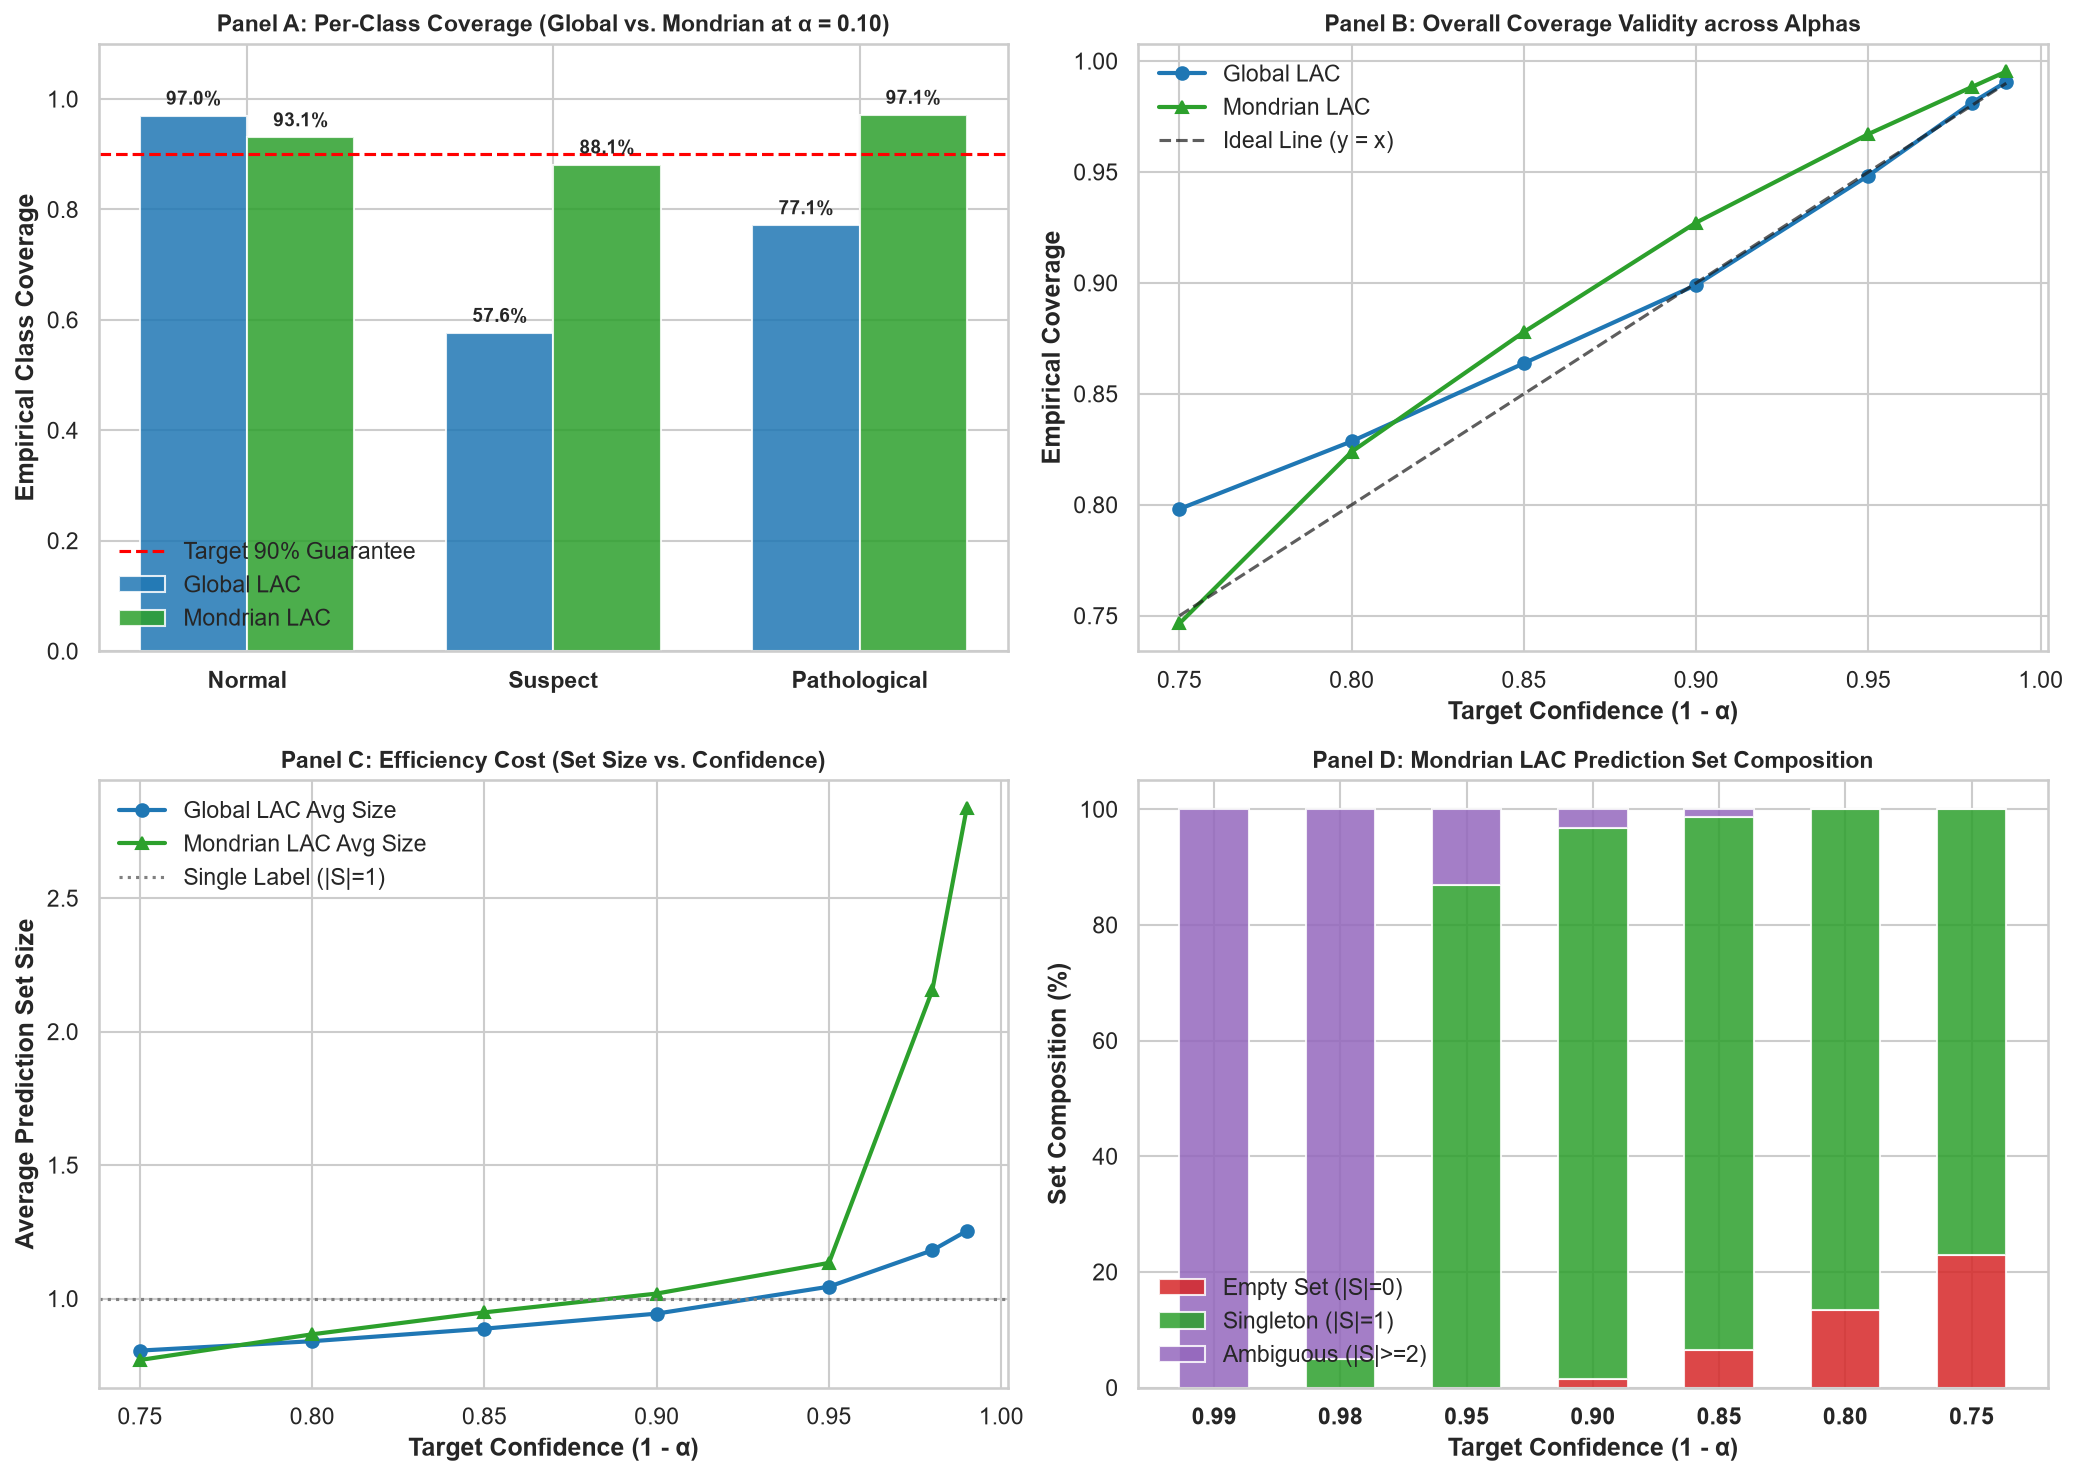

In [6]:
figure_path = PROJECT_ROOT / "reports/figures/mondrian_comparison.png"
fig = plot_mondrian_comparison(df_global_lac_sweep, df_mondrian_sweep, save_path=figure_path)
plt.show()

## 7. Conclusions on Research Question 2 (RQ2)

### RQ2 Answer:
**Yes.** Class-conditional (Mondrian) conformal prediction fundamentally fixes the minority reliability crisis in CTG classification:
1. **Minority Coverage Recovery**: Under Global LAC, Pathological coverage was only **77.14%** (missing nearly 1 in 4 sick fetuses). Mondrian conformal prediction elevates Pathological coverage to **97.14%** and Suspect coverage from **57.63% to 88.14%** (with overall marginal coverage **92.72%**).
2. **Minimal Efficiency Penalty**: Average set size increases only modestly from $0.944$ to **$1.019$ labels** — meaning **$95.31\%$ of predictions remain singletons**! The model is not needlessly outputting large sets.
3. **Major Reduction in Empty Sets**: Empty sets drop from the reported Global LAC rate (**5.63%**) down to **1.41%** (an approximately 75% reduction) under exact rank-order Mondrian calibration.
